# AICE Professional 주피터라이트 실전 모의고사 09회 — 공개데이터(반도체 결함 준위 · 법령 조문 소관부처(행정·법무 등) · 위성 지형 5종)

## [ 필독 ] AICE Professional 모의고사 유의사항

- 공식 샘플문항(가공식품 카테고리 분류)과 **같은 시험지 형식**으로 만든 모의고사입니다. 3문항, 180분 기준입니다.
- 공식 시험과 같은 **Tabular / Text / Image 3유형**입니다. 2번 Text 문항은 공식 샘플(상품명 → 카테고리)과 같은 텍스트 분류입니다.
- 본인 스스로 모델을 만들고 **달성 목표 이상의 성능**이 나오도록 개발해야 합니다. 정답(테스트 라벨)은 제공되지 않습니다.
  대신 이 노트북 **맨 마지막 셀**(전체 자동 채점, 정답 키 인코딩)로 제출 파일을 스스로 채점할 수 있습니다(연습용).

## 사용할 수 있는 라이브러리 (주피터라이트 판)

이 모의고사는 **브라우저 주피터라이트(Pyodide · Python 3.14)** 에서 설치 없이 끝까지 풀 수 있도록 라이브러리를 제한했습니다.
필요한 라이브러리는 주피터라이트에 **미리 설치**되어 있습니다. 맨 위 '브라우저 실습' 셀은 확인만 하고 바로 끝납니다(Colab·로컬 Jupyter 에서는 아무 일도 하지 않습니다).

| 구분 | 쓸 수 있음 | 쓰지 않음(브라우저에서 안 됨) |
|---|---|---|
| 데이터·그림 | numpy · pandas · matplotlib · seaborn · Pillow | — |
| 머신러닝 | scikit-learn · LightGBM · XGBoost · imbalanced-learn · joblib | CatBoost |
| 텍스트 | scikit-learn 의 CountVectorizer · TfidfVectorizer · 내장 영어 불용어, **NLTK**(불용어·토큰화·어간 추출, 데이터는 `/drive/nltk_data` 에 미리 들어 있음) | 형태소 분석기 · BERT 등 사전학습 언어 모델 |
| 딥러닝 | `tensorflow.keras` 문법(TensorFlow.js 로 실행되는 대체 구현체, 미리 설치): `Sequential`·함수형(`Input` → 층 → `Model`) · Dense · Dropout · BatchNormalization · Conv2D · MaxPooling2D · GlobalAveragePooling2D · Embedding · LSTM · GRU · 콜백 3종(EarlyStopping · ModelCheckpoint · ReduceLROnPlateau) · `load_img` · `img_to_array` · `image_dataset_from_directory` · `ImageDataGenerator` · `model.save` / `load_model` · **MobileNet v1 전이학습**(`alpha=0.25`, 224×224, `weights='imagenet'` 만) | PyTorch · 다른 사전학습 모델(MobileNetV2/V3 · ResNet · EfficientNet 등) · 사용자 정의 층·손실 · GPU |

- 이미지는 64×64 정도로 줄여 작은 CNN 을 직접 학습하거나, MobileNet v1(alpha 0.25)로 특징을 뽑아 분류기를 학습하세요(전이학습). 브라우저 TensorFlow.js 는 CPython TensorFlow 와 수치가 조금 달라 딥러닝 점수가 약간 다르게 나올 수 있습니다.
- 학습이 오래 걸리면 epoch 를 줄이거나 조기 종료(EarlyStopping)를 쓰세요. 최신 Chrome·Edge 를 권장합니다.

## 시간 배분(180분)

| 문항 | 권장 시간 | 먼저 할 일 |
|---|---|---|
| 1. Tabular (30점) | 50분 | `info()`·`describe()` 로 자료형·결측 확인 → 기본 모델로 제출 파일부터 만들기 |
| 2. Text (35점) | 60분 | 라벨 분포·문장 길이 확인 → TF-IDF + 선형 모델로 기준 점수 |
| 3. Image (35점) | 60분 | 압축 풀기·폴더 구조 확인 → 작은 CNN 으로 기준 점수 |
| 마무리 | 10분 | 제출 파일 6개 이름·열 구조 확인 → 맨 마지막 채점 셀 실행 |

## 시험 자원 가이드

| 구분 | 공식 시험 | 이 모의고사 |
|---|---|---|
| IDE | CPU 8 core · Memory 32G · GPU 1개(VRAM 16GB) | **브라우저 주피터라이트**(설치 없음, CPU) — Colab·로컬 Jupyter 에서도 그대로 실행됨 |
| SW | Python 3.10 · TensorFlow 2.13 · PyTorch 2.1 | Python 3.14(Pyodide) · scikit-learn · LightGBM · XGBoost · Keras 문법(TensorFlow.js) — 위 표의 라이브러리만 |

## 유의 사항

- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 제출 파일명은 **고정**입니다: `answer_1~3` 모델 파일과 `answer_1~3.csv`.


문제에 제시되는 가이드는 필수적으로 준수하여 주시기 바랍니다. 이를 준수하지 않을 경우 채점 제한 또는 0점 처리될 수 있으니
각별히 유의해 주시기 바랍니다.

#### **[학습 정보]**
- 학습 목표 : Tabular · Text · Image 예측 모델 3종을 만들어 달성 목표 이상의 예측 파일을 제출하고, 제출한 코드로 같은 모델이 재현되게 할 수 있다
- AICE 역량 : PT1·PT2 표 데이터 / PX1·PX2 텍스트 / PI1·PI2 이미지 / PS1 제출 파일 형식·재현성
- 제출 파일 : `answer_1~3` 모델 파일(.pkl · .h5 등)과 `answer_1~3.csv` — **파일명은 고정**입니다(이름을 바꾸면 채점되지 않음)

| 문항 | 문제 | 달성 목표 | 역량 | 기술 | 예상 시간 |
|---|---|---|---|---|---|
| 1. Tabular | 반도체 불순물 결함 준위 예측 | RMSE 0.347 이하 | PT1 표 데이터 전처리·피처 엔지니어링, PT2 표 데이터 모델 학습·평가 | pandas, scikit-learn(Ridge, RandomForestRegressor, KFold), LightGBM, joblib | 50분 |
| 2. Text | 법령 조문 소관부처 분류(행정·법무·해양·농림·교육·금융) | 정확도 0.77 이상 | PX1 텍스트 정제·벡터화, PX2 텍스트 분류 모델 학습·평가 | pandas, scikit-learn(TfidfVectorizer, LinearSVC), joblib | 60분 |
| 3. Image | 위성 영상 토지피복 분류(5종) | 정확도 0.66 이상 | PI1 이미지 로딩·전처리, PI2 이미지 분류 모델(CNN·전이학습) | pandas, Keras(TensorFlow.js) | 60분 |

In [1]:
# (브라우저 실습) 주피터라이트에는 tensorflow(TensorFlow.js 대체 구현체)·scikit-learn·LightGBM 등이 미리 설치되어 있어 이 셀은 확인만 합니다.
# Colab·로컬 Jupyter 에서는 아무 일도 하지 않습니다.
import os, sys, importlib.util
if 'pyodide' in sys.modules:
    os.environ['AICE_IMG_DIR'] = '/tmp/aice_images/' + os.path.basename(os.getcwd())   # 이미지 압축은 메모리 폴더에 풂(빠름)
    if not ('tensorflow' in sys.modules or importlib.util.find_spec('tensorflow')):
        # 미리 설치되지 않은 사이트(패치 전 주피터라이트)에서만: 같은 폴더의 tfjs_keras.py 를 불러옵니다
        sys.path[:0] = [os.getcwd(), '/drive']
        import tfjs_keras
        await tfjs_keras.load()
print('준비 완료 — 다음 셀로 넘어가세요.')

준비 완료 — 다음 셀로 넘어가세요.


## 1. Tabular 문제 - 반도체 불순물 결함 준위 예측 (30점)

<sub>학습 목표: 반도체 불순물 결함 준위 예측 모델로 테스트 RMSE 0.347 이하을 달성할 수 있다 | 역량: PT1 표 데이터 전처리·피처 엔지니어링, PT2 표 데이터 모델 학습·평가 | 기술: pandas, scikit-learn(Ridge, RandomForestRegressor, KFold), LightGBM, joblib | 난이도: 실전 | 예상 시간: 50분</sub>

### 문제 개요

화합물 반도체(CdS·GaAs 등)에 불순물이 들어갔을 때 생기는 **결함 준위(eV, 가전자대 위쪽 기준)** 를 모체 물질·불순물·자리 정보와 물성 값으로 예측하는 회귀 문제입니다. 범주형(모체 물질·불순물·자리)과 0/1 표시 열, 수치 물성 열이 섞여 있습니다.

제공된 훈련 데이터셋을 활용해 회귀 모델을 개발하고, 테스트 데이터셋의 'pbe_level' 값을 예측하시기 바랍니다.

### 달성 목표

"01_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **RMSE 0.347 이하**를 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `01_train.csv`: 훈련 데이터셋입니다. 훈련 데이터셋으로 모델을 만드세요.
- `01_test_x.csv`: 테스트 데이터셋입니다. 라벨('pbe_level') 값이 제외되어 있습니다.

**Label 정보**

- 'pbe_level' : PBE 계산으로 구한 결함 준위(eV)

**Data 정보**

- 'id' : 행 번호
- 'host_material · host_element_a · host_element_b' : 모체 물질과 구성 원소
- 'impurity · removed_element · site · site_type' : 들어간 불순물 · 빠진 원소 · 들어간 자리
- 'is_* · M_*' : 자리 종류·원소 0/1 표시
- 'charge_from · charge_to' : 전하 상태 변화
- 'host_bandgap · host_lattice · host_epsilon' : 모체의 띠간격(eV) · 격자 상수(Å) · 유전율

**데이터 출처** — Semiconductor defect levels v1.1(HF foundry-ml/semiconductor_defectlevels_v1-1, Polak et al. 2022 · CC-BY-4.0) — 화합물 반도체 2,910건

### 데이터 예시

`01_train.csv`

| id | host_material | host_element_a | host_element_b | impurity | removed_element | site_type | site | … |
|---|---|---|---|---|---|---|---|---|
| 865 | InSb | In | Sb | Bi | In | 3 | M_In | … |
| 177 | CdSe | Cd | Se | Se | Cd | 3 | M_Cd | … |
| 2747 | CdTeSe | Cd | TeSe | Al | Cd | 3 | M_Cd | … |

`01_test_x.csv`

| id | host_material | host_element_a | host_element_b | impurity | removed_element | site_type | site | … |
|---|---|---|---|---|---|---|---|---|
| 128 | CdS | Cd | S | Al | 0 | int_3 | M_i_Cd_site | … |
| 2900 | AlSb | Al | Sb | Bi | Al | 3 | M_Al | … |
| 2882 | AlSb | Al | Sb | Sb | Al | 3 | M_Al | … |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 반도체 불순물 결함 준위 예측 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_1.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('pbe_level') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_1.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 'pbe_level' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 'pbe_level' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 문자열 범주(host_material·impurity·site 등)는 원-핫 인코딩합니다. 테스트에만 있는 범주가 있을 수 있어 열을 맞춰야(`reindex`) 합니다.
- 선형 모델과 트리 기반 모델(RandomForest·LightGBM)을 **K-Fold 교차검증 RMSE** 로 비교해 보세요.
- 평가 지표는 **RMSE**(낮을수록 좋음)입니다. 예측값은 eV 단위 실수로 제출하세요.

### 채점 진행 방식 안내

- 1번 문항 배점 : 30점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_1.csv 로 제출된 예측 데이터를 정답지와 대조하여, **RMSE 0.3817 이하** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

In [2]:

import pandas as pd

train_1 = pd.read_csv('01_train.csv')
test_1 = pd.read_csv('01_test_x.csv')
label_1 = 'pbe_level'

print('학습 데이터:', train_1.shape)
print('테스트 데이터:', test_1.shape)
print('입력 컬럼 일치:', train_1.drop(columns=label_1).columns.equals(test_1.columns))

print('\n컬럼별 자료형과 결측치')
column_info_1 = pd.DataFrame({
    '자료형': train_1.drop(columns=label_1).dtypes.astype(str),
    '학습 결측': train_1.drop(columns=label_1).isna().sum(),
    '테스트 결측': test_1.isna().sum(),
    '고유값 수': train_1.drop(columns=label_1).nunique()
})
print(column_info_1.to_string())

print('\n정답 결측치:', train_1[label_1].isna().sum())
print('\n정답 pbe_level 통계')
print(train_1[label_1].describe().round(4))

print('\n모체 물질별 데이터 수')
print(train_1['host_material'].value_counts())

print('\n범주형 컬럼')
print(train_1.select_dtypes(include='object').columns.tolist())


학습 데이터: (2328, 34)
테스트 데이터: (582, 33)
입력 컬럼 일치: True

컬럼별 자료형과 결측치
                       자료형  학습 결측  테스트 결측  고유값 수
id                   int64      0       0   2328
host_material       object      0       0     14
host_element_a      object      0       0      4
host_element_b      object      0       0      8
impurity            object      0       0     63
removed_element     object      0       0     11
site_type           object      0       0      5
site                object      0       0     15
is_a_latt            int64      0       0      2
is_interstitial      int64      0       0      2
is_interstitial_a    int64      0       0      2
is_interstitial_b    int64      0       0      2
is_interstitial_n    int64      0       0      2
M_Al                 int64      0       0      2
M_As                 int64      0       0      2
M_Cd                 int64      0       0      2
M_Ga                 int64      0       0      2
M_In                 int64      0       0      2
M_

In [3]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X_1 = train_1.drop(columns=['id', label_1])
y_1 = train_1[label_1]

cat_cols_1 = X_1.select_dtypes(include='object').columns.tolist()
num_cols_1 = X_1.select_dtypes(include='number').columns.tolist()

X_train_1, X_valid_1, y_train_1, y_valid_1 = train_test_split(
    X_1,
    y_1,
    test_size=0.2,
    random_state=42,
    stratify=X_1['host_material']
)

preprocessor_1 = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_1),
    ('num', StandardScaler(), num_cols_1)
])

print('학습 입력:', X_train_1.shape)
print('검증 입력:', X_valid_1.shape)
print('학습 정답:', y_train_1.shape)
print('검증 정답:', y_valid_1.shape)

print('\n변수 구성')
print('범주형:', len(cat_cols_1), '개')
print('수치형:', len(num_cols_1), '개')

print('\n모체 물질별 비율 (%)')
distribution_1 = pd.DataFrame({
    '전체': X_1['host_material'].value_counts(normalize=True) * 100,
    '학습': X_train_1['host_material'].value_counts(normalize=True) * 100,
    '검증': X_valid_1['host_material'].value_counts(normalize=True) * 100
})
print(distribution_1.round(2).to_string())


학습 입력: (1862, 32)
검증 입력: (466, 32)
학습 정답: (1862,)
검증 정답: (466,)

변수 구성
범주형: 7 개
수치형: 25 개

모체 물질별 비율 (%)
                  전체     학습     검증
host_material                     
AlAs            1.12   1.13   1.07
AlP             1.33   1.34   1.29
AlSb            1.20   1.18   1.29
CdS             6.92   6.93   6.87
CdSe            6.74   6.77   6.65
CdSeS           4.73   4.73   4.72
CdTe           65.51  65.52  65.45
CdTeSe          4.42   4.40   4.51
GaAs            1.42   1.40   1.50
GaP             1.33   1.34   1.29
GaSb            1.42   1.40   1.50
InAs            1.33   1.34   1.29
InP             1.33   1.34   1.29
InSb            1.20   1.18   1.29


In [4]:

import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor

models_1 = {
    'Ridge': Ridge(
        alpha=10.0,
        solver='lsqr'
    ),
    'RandomForest': RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    'LightGBM': LGBMRegressor(
        n_estimators=300,
        learning_rate=0.04,
        num_leaves=15,
        min_child_samples=15,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

cv_1 = KFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

results_1 = []
fitted_models_1 = {}

for name, model in models_1.items():
    pipe = Pipeline([
        ('preprocessor', clone(preprocessor_1)),
        ('model', model)
    ])

    cv_scores = -cross_val_score(
        pipe,
        X_train_1,
        y_train_1,
        cv=cv_1,
        scoring='neg_root_mean_squared_error',
        n_jobs=1
    )

    pipe.fit(X_train_1, y_train_1)
    valid_pred = pipe.predict(X_valid_1)

    valid_rmse = np.sqrt(
        mean_squared_error(y_valid_1, valid_pred)
    )

    results_1.append({
        '모델': name,
        'CV RMSE': cv_scores.mean(),
        'CV 표준편차': cv_scores.std(),
        '검증 RMSE': valid_rmse
    })

    fitted_models_1[name] = pipe

results_df_1 = pd.DataFrame(results_1)
results_df_1 = results_df_1.sort_values('CV RMSE')

print(results_df_1.round(4).to_string(index=False))
print('\nCV 1위:', results_df_1.iloc[0]['모델'])


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


          모델  CV RMSE  CV 표준편차  검증 RMSE
    LightGBM   0.3703   0.0046   0.3415
RandomForest   0.4136   0.0088   0.4055
       Ridge   0.4279   0.0058   0.4004

CV 1위: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [5]:

params_1a = {
    'A_보수적': {
        'n_estimators': 450,
        'learning_rate': 0.03,
        'num_leaves': 12,
        'min_child_samples': 30,
        'reg_lambda': 1.0
    },
    'B_균형형': {
        'n_estimators': 450,
        'learning_rate': 0.035,
        'num_leaves': 20,
        'min_child_samples': 20,
        'reg_lambda': 1.0
    },
    'C_복잡한패턴': {
        'n_estimators': 400,
        'learning_rate': 0.035,
        'num_leaves': 31,
        'min_child_samples': 15,
        'reg_lambda': 1.0
    },
    'D_작은트리': {
        'n_estimators': 500,
        'learning_rate': 0.025,
        'num_leaves': 10,
        'min_child_samples': 15,
        'reg_lambda': 0.5
    },
    'E_규제강화': {
        'n_estimators': 500,
        'learning_rate': 0.03,
        'num_leaves': 15,
        'min_child_samples': 25,
        'reg_lambda': 3.0
    }
}

results_1a = []

for name, params in params_1a.items():
    model = LGBMRegressor(
        **params,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )

    pipe = Pipeline([
        ('preprocessor', clone(preprocessor_1)),
        ('model', model)
    ])

    scores = -cross_val_score(
        pipe,
        X_train_1,
        y_train_1,
        cv=cv_1,
        scoring='neg_root_mean_squared_error',
        n_jobs=1
    )

    results_1a.append({
        '설정': name,
        'CV RMSE': scores.mean(),
        'CV 표준편차': scores.std()
    })

results_df_1a = pd.DataFrame(results_1a)

baseline_1a = pd.DataFrame([{
    '설정': '기존 LightGBM',
    'CV RMSE': results_df_1.loc[
        results_df_1['모델'] == 'LightGBM',
        'CV RMSE'
    ].iloc[0],
    'CV 표준편차': results_df_1.loc[
        results_df_1['모델'] == 'LightGBM',
        'CV 표준편차'
    ].iloc[0]
}])

comparison_1a = pd.concat(
    [baseline_1a, results_df_1a],
    ignore_index=True
).sort_values('CV RMSE')

print('LightGBM 설정별 교차검증 결과')
print(comparison_1a.round(4).to_string(index=False))

best_name_1a = comparison_1a.iloc[0]['설정']
print('\nCV 최고 설정:', best_name_1a)

if best_name_1a != '기존 LightGBM':
    best_model_1a = Pipeline([
        ('preprocessor', clone(preprocessor_1)),
        ('model', LGBMRegressor(
            **params_1a[best_name_1a],
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        ))
    ])

    best_model_1a.fit(X_train_1, y_train_1)

    pred_1a = best_model_1a.predict(X_valid_1)
    rmse_1a = np.sqrt(mean_squared_error(y_valid_1, pred_1a))

    print('신규 후보 검증 RMSE:', round(rmse_1a, 4))
else:
    best_model_1a = fitted_models_1['LightGBM']
    print('기존 후보 검증 RMSE:',
          round(results_df_1.loc[
              results_df_1['모델'] == 'LightGBM',
              '검증 RMSE'
          ].iloc[0], 4))


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

LightGBM 설정별 교차검증 결과
         설정  CV RMSE  CV 표준편차
    C_복잡한패턴   0.3644   0.0033
기존 LightGBM   0.3703   0.0046
     D_작은트리   0.3768   0.0037
      B_균형형   0.3968   0.0094
     E_규제강화   0.4125   0.0073
      A_보수적   0.4212   0.0085

CV 최고 설정: C_복잡한패턴
신규 후보 검증 RMSE: 0.3232


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [6]:

import joblib
import numpy as np
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# C 모델 전체 재학습
final_model_1 = Pipeline([
    ('preprocessor', clone(preprocessor_1)),
    ('model', LGBMRegressor(
        **params_1a['C_복잡한패턴'],
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ))
])

final_model_1.fit(X_1, y_1)

# 후보 모델 저장 및 재불러오기
model_path_1 = Path('answer_1_candidate_C.pkl')
csv_path_1 = Path('answer_1_candidate_C.csv')

if model_path_1.exists() or csv_path_1.exists():
    raise FileExistsError('후보 파일이 이미 존재합니다. 기존 파일을 확인하세요.')

joblib.dump(final_model_1, model_path_1)
loaded_model_1 = joblib.load(model_path_1)

# 테스트 데이터 예측
test_features_1 = test_1[X_1.columns]

pred_before_1 = final_model_1.predict(test_features_1)
pred_after_1 = loaded_model_1.predict(test_features_1)

prediction_match_1 = np.allclose(
    pred_before_1,
    pred_after_1,
    rtol=1e-10,
    atol=1e-10
)

assert prediction_match_1, '모델 저장 전후 예측값 불일치'
assert len(pred_after_1) == len(test_1), '예측 행 수 불일치'
assert np.isfinite(pred_after_1).all(), '비정상 예측값 존재'

# 테스트 원본 컬럼 유지 후 예측 컬럼 추가
submission_1 = test_1.copy()
submission_1[label_1] = pred_after_1

submission_1.to_csv(csv_path_1, index=False)

# 저장된 CSV 다시 읽어 검증
check_1 = pd.read_csv(csv_path_1)

assert len(check_1) == len(test_1)
assert check_1.columns.tolist() == (
    test_1.columns.tolist() + [label_1]
)
assert check_1['id'].equals(test_1['id'])
assert np.allclose(
    check_1[label_1].values,
    pred_after_1,
    rtol=1e-10,
    atol=1e-10
)

print('전체 학습 데이터:', X_1.shape)
print('테스트 데이터:', test_features_1.shape)
print('모델 저장 전후 예측 일치:', prediction_match_1)
print('CSV 행 수:', len(check_1))
print('CSV 컬럼 수:', len(check_1.columns))
print('예측 결측치:', check_1[label_1].isna().sum())

print('\n예측값 통계')
print(check_1[label_1].describe().round(4))

print('\nCSV 미리보기')
print(check_1[['id', label_1]].head(10).to_string(index=False))

print('\n후보 모델:', model_path_1)
print('후보 CSV:', csv_path_1)
print('모델 크기:', round(model_path_1.stat().st_size / 1024, 1), 'KB')


전체 학습 데이터: (2328, 32)
테스트 데이터: (582, 32)
모델 저장 전후 예측 일치: True
CSV 행 수: 582
CSV 컬럼 수: 34
예측 결측치: 0

예측값 통계
count    582.0000
mean       0.9189
std        1.1334
min       -1.5472
25%       -0.0019
50%        1.0018
75%        1.8885
max        3.2412
Name: pbe_level, dtype: float64

CSV 미리보기
  id  pbe_level
 128   2.893314
2900   2.365584
2882  -0.951125
 213   2.239654
 370  -0.033362
 464   0.978042
 916  -0.249125
 741  -1.329002
2631   2.416729
 465   0.059264

후보 모델: answer_1_candidate_C.pkl
후보 CSV: answer_1_candidate_C.csv
모델 크기: 1230.2 KB


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [7]:

import shutil
from pathlib import Path
import pandas as pd

candidate_files_1 = {
    Path('answer_1_candidate_C.pkl'): Path('answer_1.pkl'),
    Path('answer_1_candidate_C.csv'): Path('answer_1.csv')
}

# 후보 파일 존재 여부 확인
for src in candidate_files_1:
    if not src.is_file():
        raise FileNotFoundError(f'후보 파일 없음: {src}')

# 기존 정식 제출 파일 보호
for dst in candidate_files_1.values():
    if dst.exists():
        raise FileExistsError(f'기존 제출 파일 보호: {dst}')

# 정식 파일 생성
for src, dst in candidate_files_1.items():
    shutil.copy2(src, dst)

# 복사 후 내용 검증
for src, dst in candidate_files_1.items():
    assert src.read_bytes() == dst.read_bytes()

check_final_1 = pd.read_csv('answer_1.csv')

assert len(check_final_1) == len(test_1)
assert check_final_1.columns.tolist() == (
    test_1.columns.tolist() + [label_1]
)
assert check_final_1['id'].equals(test_1['id'])
assert check_final_1[label_1].notna().all()

print('1번 정식 제출 파일 생성 완료')
print('모델: answer_1.pkl')
print('예측: answer_1.csv')
print('제출 CSV:', check_final_1.shape)
print('후보 파일과 정식 파일 일치: True')


1번 정식 제출 파일 생성 완료
모델: answer_1.pkl
예측: answer_1.csv
제출 CSV: (582, 34)
후보 파일과 정식 파일 일치: True


<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

자료형·결측·정답 분포를 확인합니다. 번호·날짜 원문·누수 열은 빼고 범주형은 원-핫 인코딩합니다. '참고'의 파생 변수를 만든 뒤 선형 모델과 트리 모델(LightGBM 등)을 **교차검증 RMSE** 로 비교해 더 나은 쪽으로 전체 학습하세요.

- 이 문항의 핵심: 문자열 범주(host_material·impurity·site 등)는 원-핫 인코딩합니다. 테스트에만 있는 범주가 있을 수 있어 열을 맞춰야(`reindex`) 합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `pandas`, `joblib`, `Ridge`, `RandomForestRegressor`, `LGBMRegressor`, `KFold`, `cross_val_score`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html>
- 참고 문서: <https://lightgbm.readthedocs.io/en/latest/pythonapi/lightgbm.LGBMRegressor.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html>

</details>

<details><summary>힌트 3단계 (코드 구조) - 1번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
from sklearn.linear_model import ____
from sklearn.ensemble import ____
from lightgbm import ____
from sklearn.model_selection import ____, ____

train = pd.read_csv('01_train.csv')
test = pd.read_csv('01_test_x.csv')
train.info(verbose=False)
LABEL = '____'


# ▷ 후보 모델을 교차검증으로 비교(점수 출력)
# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_1.pkl`(모델) · `answer_1.csv`(예측)

</details>

## 2. Text 문제 - 법령 조문 소관부처 분류(행정·법무·해양·농림·교육·금융) (35점)

<sub>학습 목표: 법령 조문 소관부처 분류(행정·법무·해양·농림·교육·금융) 모델로 테스트 정확도 0.77 이상을 달성할 수 있다 | 역량: PX1 텍스트 정제·벡터화, PX2 텍스트 분류 모델 학습·평가 | 기술: pandas, scikit-learn(TfidfVectorizer, LinearSVC), joblib | 난이도: 실전 | 예상 시간: 60분</sub>

### 문제 개요

법령의 조문(제목·내용) 텍스트로 그 법령을 맡은 **소관부처** 를 분류하는 자연어 처리(Text Classification) 문제입니다. 공식 샘플문항(가공식품 상품명 → 카테고리)과 같은 형식입니다.

제공된 훈련 데이터셋을 활용해 텍스트 다중 분류(6종) 모델을 개발하고, 테스트 데이터셋의 '소관부처' 값을 예측하시기 바랍니다.

### 달성 목표

"02_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 77% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `02_train.csv`: 훈련 데이터셋입니다. 훈련 데이터셋으로 모델을 만드세요.
- `02_test_x.csv`: 테스트 데이터셋입니다. 라벨('소관부처') 값이 제외되어 있습니다.

**Label 정보**

- '소관부처' : 행정안전부 / 법무부 / 해양수산부 / 농림축산식품부 / 교육부 / 금융위원회

**Data 정보**

- '조문제목' : 조문의 제목(예: 목적, 정의, 벌칙)
- '조문내용' : 조문 본문(앞 300자)
- 'id' : 테스트 행 번호(테스트에만)

**데이터 출처** — 한국 법령 조문(HF smhilee/korean-law-dataset) — 행정안전부·법무부·해양수산부·농림축산식품부·교육부·금융위원회 조문, 조문 내용은 앞 300자

### 데이터 예시

`02_train.csv`

| 조문제목 | 조문내용 | 소관부처 |
|---|---|---|
| 심판 비용 | 제78조(심판 비용) 법 제98조에서 준용하는 「특허법」 제165조제5항에 따른 심판에 관한 비용의 결정을 청구하려는 자는 그 청구서에 필요한 계산서와 증명서류를 첨부하여 심판위원회위원장에게 제출하여야 한다. | 농림축산식품부 |
| 청원서의 제출 방법 | 제7조(청원서의 제출 방법) 법 제11조제1항에 따른 청원서의 제출은 청원기관에 직접 제출하거나 우편, 팩스 또는 온라인청원시스템을 통해 제출하는 방법으로 한다. | 행정안전부 |
| 전직 대통령에 의한 대통령지정기록물의 지정 해제 요구 절차 | 제10조의8(전직 대통령에 의한 대통령지정기록물의 지정 해제 요구 절차) | 행정안전부 |

`02_test_x.csv`

| id | 조문제목 | 조문내용 |
|---|---|---|
| 1 | 지분압류채권자의 보호 | 제249조(지분압류채권자의 보호) 회사가 제247조제4항의 규정에 위반하여 그 재산을 처분한 때에는 사원의 지분을 압류한 자는 회사에 대하여 그 지분에 상당하는 금액의 지급을 청구할 수 있다. 이 경우에는 전조의 규정을 준용한다. |
| 2 | (통상실시권 설정에 관한 재정의 예외) | 제37조(통상실시권 설정에 관한 재정의 예외) 법 제67조제1항제1호에서 "대통령령으로 정하는 정당한 사유"란 다음 각 호의 어느 하나에 해당하는 경우를 말한다. |
| 3 | 학교장의 관리ㆍ감독하의 질병 | 제3조(학교장의 관리ㆍ감독하의 질병) 법 제2조제6호에서 "대통령령이 정하는 것"이란 다음 각 호의 어느 하나에 해당하는 질병을 말한다. |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 법령 조문 소관부처 분류(행정·법무·해양·농림·교육·금융) 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_2.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('소관부처') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_2.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 '소관부처' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 '소관부처' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 한국어는 조사·어미가 붙어 단어가 여러 모양으로 나옵니다. **문자 n-gram**(TfidfVectorizer(analyzer='char_wb'))이 잘 맞습니다.
- 학습 라벨 분포: 농림축산식품부 1200, 행정안전부 1200, 법무부 1200, 해양수산부 1200, 교육부 996, 금융위원회 748 — 부처마다 건수가 달라 클래스 불균형이 조금 있습니다.
- 평가 지표는 **정확도(Accuracy)** 입니다. 테스트 행 순서(`id`)를 그대로 유지해 제출하세요.

### 채점 진행 방식 안내

- 2번 문항 배점 : 35점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_2.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 69.3% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

In [9]:

import pandas as pd

train_2 = pd.read_csv('02_train.csv')
test_2 = pd.read_csv('02_test_x.csv')
label_2 = '소관부처'

print('학습 데이터:', train_2.shape)
print('테스트 데이터:', test_2.shape)

print('\n학습 컬럼:', train_2.columns.tolist())
print('테스트 컬럼:', test_2.columns.tolist())

print('\n학습 데이터 결측치')
print(train_2.isna().sum())

print('\n테스트 데이터 결측치')
print(test_2.isna().sum())

print('\n소관부처별 데이터 분포')
label_dist_2 = pd.DataFrame({
    '데이터 수': train_2[label_2].value_counts(),
    '비율(%)': train_2[label_2].value_counts(normalize=True) * 100
})
print(label_dist_2.round(2).to_string())

print('\n문장 길이 통계')
for col in ['조문제목', '조문내용']:
    lengths = train_2[col].fillna('').str.len()
    print(col)
    print(lengths.describe().round(2).to_string())

print('\n완전 중복 행:', train_2.duplicated().sum())

text_2 = (
    train_2['조문제목'].fillna('').str.strip()
    + ' '
    + train_2['조문내용'].fillna('').str.strip()
)

print('동일 텍스트 중복:', text_2.duplicated().sum())
print('정답 결측치:', train_2[label_2].isna().sum())


학습 데이터: (6544, 3)
테스트 데이터: (1636, 3)

학습 컬럼: ['조문제목', '조문내용', '소관부처']
테스트 컬럼: ['id', '조문제목', '조문내용']

학습 데이터 결측치
조문제목    895
조문내용      0
소관부처      0
dtype: int64

테스트 데이터 결측치
id        0
조문제목    225
조문내용      0
dtype: int64

소관부처별 데이터 분포
         데이터 수  비율(%)
소관부처                 
농림축산식품부   1200  18.34
행정안전부     1200  18.34
법무부       1200  18.34
해양수산부     1200  18.34
교육부        996  15.22
금융위원회      748  11.43

문장 길이 통계
조문제목
count    6544.00
mean       10.65
std         7.65
min         0.00
25%         4.00
50%        11.00
75%        16.00
max        50.00
조문내용
count    6544.00
mean       75.44
std        57.19
min        20.00
25%        26.00
50%        62.00
75%       108.00
max       300.00

완전 중복 행: 0
동일 텍스트 중복: 8
정답 결측치: 0


In [10]:

import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

def prepare_text_2(df):
    title = df['조문제목'].fillna('').astype(str)
    content = df['조문내용'].fillna('').astype(str)

    title = title.str.replace(r'\s+', ' ', regex=True).str.strip()
    content = content.str.replace(r'\s+', ' ', regex=True).str.strip()

    return (title + ' ' + content).str.strip()

# 학습·테스트 텍스트 생성
X_2 = prepare_text_2(train_2)
X_test_2 = prepare_text_2(test_2)
y_2 = train_2[label_2]

# 동일 텍스트에 동일한 그룹 번호 부여
groups_2 = pd.factorize(X_2)[0]

# 그룹과 클래스 비율을 고려한 분리
splitter_2 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx_2, valid_idx_2 = next(
    splitter_2.split(X_2, y_2, groups=groups_2)
)

X_train_2 = X_2.iloc[train_idx_2]
X_valid_2 = X_2.iloc[valid_idx_2]

y_train_2 = y_2.iloc[train_idx_2]
y_valid_2 = y_2.iloc[valid_idx_2]

groups_train_2 = groups_2[train_idx_2]

print('학습 데이터:', X_train_2.shape)
print('검증 데이터:', X_valid_2.shape)
print('테스트 데이터:', X_test_2.shape)

print('\n학습·검증 동일 텍스트 수:',
      len(set(X_train_2) & set(X_valid_2)))

print('\n소관부처별 비율 (%)')
distribution_2 = pd.DataFrame({
    '전체': y_2.value_counts(normalize=True) * 100,
    '학습': y_train_2.value_counts(normalize=True) * 100,
    '검증': y_valid_2.value_counts(normalize=True) * 100
})
print(distribution_2.round(2).to_string())

print('\n전처리 후 빈 문장')
print('학습:', (X_train_2 == '').sum())
print('검증:', (X_valid_2 == '').sum())
print('테스트:', (X_test_2 == '').sum())

print('\n전처리 예시')
print(X_train_2.iloc[0][:250])


학습 데이터: (5236,)
검증 데이터: (1308,)
테스트 데이터: (1636,)

학습·검증 동일 텍스트 수: 0

소관부처별 비율 (%)
            전체     학습     검증
소관부처                        
교육부      15.22  15.07  15.83
금융위원회    11.43  11.44  11.39
농림축산식품부  18.34  18.14  19.11
법무부      18.34  18.26  18.65
해양수산부    18.34  18.47  17.81
행정안전부    18.34  18.62  17.20

전처리 후 빈 문장
학습: 0
검증: 0
테스트: 0

전처리 예시
심판 비용 제78조(심판 비용) 법 제98조에서 준용하는 「특허법」 제165조제5항에 따른 심판에 관한 비용의 결정을 청구하려는 자는 그 청구서에 필요한 계산서와 증명서류를 첨부하여 심판위원회위원장에게 제출하여야 한다.


In [11]:

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score

models_2 = {
    'Char TF-IDF + LinearSVC': Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=(2, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=120000
        )),
        ('model', LinearSVC(C=1.0, random_state=42))
    ]),

    'Char TF-IDF + LogisticRegression': Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=(2, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=120000
        )),
        ('model', LogisticRegression(
            C=3.0,
            max_iter=2000,
            random_state=42
        ))
    ]),

    'Word TF-IDF + LinearSVC': Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer='word',
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True,
            max_features=75000
        )),
        ('model', LinearSVC(C=1.0, random_state=42))
    ]),

    'Word TF-IDF + MultinomialNB': Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer='word',
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True,
            max_features=75000
        )),
        ('model', MultinomialNB(alpha=0.5))
    ])
}

cv_2 = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

results_2 = []
fitted_models_2 = {}

for name, pipe in models_2.items():

    cv_scores = cross_val_score(
        pipe,
        X_train_2,
        y_train_2,
        groups=groups_train_2,
        cv=cv_2,
        scoring='accuracy',
        n_jobs=1
    )

    pipe.fit(X_train_2, y_train_2)
    valid_pred = pipe.predict(X_valid_2)

    valid_acc = accuracy_score(y_valid_2, valid_pred)
    valid_f1 = f1_score(
        y_valid_2,
        valid_pred,
        average='macro'
    )

    results_2.append({
        '모델': name,
        'CV Accuracy': cv_scores.mean(),
        'CV 표준편차': cv_scores.std(),
        '검증 Accuracy': valid_acc,
        'Macro F1': valid_f1
    })

    fitted_models_2[name] = pipe

results_df_2 = pd.DataFrame(results_2)
results_df_2 = results_df_2.sort_values(
    'CV Accuracy',
    ascending=False
)

print('모델별 성능 비교')
print(results_df_2.round(4).to_string(index=False))

print('\nCV 1위:', results_df_2.iloc[0]['모델'])

print('\n검증 Accuracy 1위:',
      results_df_2.sort_values(
          '검증 Accuracy',
          ascending=False
      ).iloc[0]['모델'])


모델별 성능 비교
                              모델  CV Accuracy  CV 표준편차  검증 Accuracy  Macro F1
         Char TF-IDF + LinearSVC       0.7996   0.0099       0.8089    0.8065
Char TF-IDF + LogisticRegression       0.7777   0.0074       0.7982    0.7945
         Word TF-IDF + LinearSVC       0.5833   0.0081       0.6193    0.6142
     Word TF-IDF + MultinomialNB       0.5346   0.0114       0.5642    0.5486

CV 1위: Char TF-IDF + LinearSVC

검증 Accuracy 1위: Char TF-IDF + LinearSVC


In [13]:

import time
from sklearn.base import clone

best_name_2 = 'Char TF-IDF + LinearSVC'

final_model_2 = clone(fitted_models_2[best_name_2])

print('전체 데이터 재학습 시작:', len(X_2), '건', flush=True)

start_2 = time.perf_counter()

final_model_2.fit(X_2, y_2)

elapsed_2 = time.perf_counter() - start_2

print('전체 재학습 완료')
print('학습 소요 시간:', round(elapsed_2, 2), '초')
print('학습 클래스:', final_model_2.classes_)
print('TF-IDF 특성 수:',
      len(final_model_2.named_steps['tfidf'].vocabulary_))


전체 데이터 재학습 시작: 6544 건
전체 재학습 완료
학습 소요 시간: 6.94 초
학습 클래스: ['교육부' '금융위원회' '농림축산식품부' '법무부' '해양수산부' '행정안전부']
TF-IDF 특성 수: 78702


In [14]:

import joblib
import numpy as np
import pandas as pd
from pathlib import Path

# 기존에 학습 완료한 final_model_2 사용
model_path_2 = Path('answer_2_candidate_LinearSVC.pkl')
csv_path_2 = Path('answer_2_candidate_LinearSVC.csv')

# 기존 후보 파일 보호
if model_path_2.exists() or csv_path_2.exists():
    raise FileExistsError('후보 파일이 이미 존재합니다.')

# 모델 저장 및 재불러오기
joblib.dump(final_model_2, model_path_2)
loaded_model_2 = joblib.load(model_path_2)

# 테스트 예측
pred_before_2 = final_model_2.predict(X_test_2)
pred_after_2 = loaded_model_2.predict(X_test_2)

prediction_match_2 = np.array_equal(
    pred_before_2,
    pred_after_2
)

assert prediction_match_2, '저장 전후 예측값 불일치'
assert len(pred_after_2) == len(test_2), '예측 행 수 불일치'
assert pd.notna(pred_after_2).all(), '예측 결측치 존재'
assert set(pred_after_2).issubset(set(y_2.unique())), '잘못된 라벨 존재'

# 원본 테스트 컬럼 유지
submission_2 = test_2.copy()
submission_2[label_2] = pred_after_2

submission_2.to_csv(csv_path_2, index=False)

# 저장된 CSV 검증
check_2 = pd.read_csv(csv_path_2)

assert check_2.shape == (1636, 4)
assert check_2.columns.tolist() == (
    test_2.columns.tolist() + [label_2]
)
assert check_2['id'].equals(test_2['id'])
assert np.array_equal(
    check_2[label_2].values,
    pred_after_2
)

print('모델 저장 전후 예측 일치:', prediction_match_2)
print('CSV 크기:', check_2.shape)
print('예측 결측치:', check_2[label_2].isna().sum())

print('\n예측 부처별 분포')
print(check_2[label_2].value_counts().to_string())

print('\nCSV 미리보기')
print(check_2[['id', label_2]].head(10).to_string(index=False))

print('\n후보 모델:', model_path_2)
print('후보 CSV:', csv_path_2)
print('모델 크기:',
      round(model_path_2.stat().st_size / 1024 / 1024, 2),
      'MB')


모델 저장 전후 예측 일치: True
CSV 크기: (1636, 4)
예측 결측치: 0

예측 부처별 분포
소관부처
법무부        308
행정안전부      305
해양수산부      298
농림축산식품부    283
교육부        251
금융위원회      191

CSV 미리보기
 id    소관부처
  1     법무부
  2 농림축산식품부
  3     교육부
  4     법무부
  5     교육부
  6 농림축산식품부
  7     법무부
  8 농림축산식품부
  9 농림축산식품부
 10     교육부

후보 모델: answer_2_candidate_LinearSVC.pkl
후보 CSV: answer_2_candidate_LinearSVC.csv
모델 크기: 6.56 MB


In [15]:

import shutil
import hashlib
from pathlib import Path
import pandas as pd

candidate_files_2 = {
    Path('answer_2_candidate_LinearSVC.pkl'): Path('answer_2.pkl'),
    Path('answer_2_candidate_LinearSVC.csv'): Path('answer_2.csv')
}

# 후보 파일 확인
for src in candidate_files_2:
    if not src.is_file():
        raise FileNotFoundError(f'후보 파일 없음: {src}')

# 기존 정식 제출 파일 보호
for dst in candidate_files_2.values():
    if dst.exists():
        raise FileExistsError(f'기존 제출 파일 보호: {dst}')

# 정식 제출 파일 생성
for src, dst in candidate_files_2.items():
    shutil.copy2(src, dst)

# 파일 내용 동일 여부 검증
for src, dst in candidate_files_2.items():
    src_hash = hashlib.sha256(src.read_bytes()).hexdigest()
    dst_hash = hashlib.sha256(dst.read_bytes()).hexdigest()
    assert src_hash == dst_hash, f'파일 불일치: {dst}'

# 최종 CSV 검증
check_final_2 = pd.read_csv('answer_2.csv')

assert check_final_2.shape == (1636, 4)
assert check_final_2.columns.tolist() == (
    test_2.columns.tolist() + [label_2]
)
assert check_final_2['id'].equals(test_2['id'])
assert check_final_2[label_2].notna().all()
assert set(check_final_2[label_2]).issubset(set(y_2.unique()))

print('2번 정식 제출 파일 생성 완료')
print('모델: answer_2.pkl')
print('예측: answer_2.csv')
print('제출 CSV:', check_final_2.shape)
print('후보 파일과 정식 파일 일치: True')


2번 정식 제출 파일 생성 완료
모델: answer_2.pkl
예측: answer_2.csv
제출 CSV: (1636, 4)
후보 파일과 정식 파일 일치: True


<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

라벨 분포와 문장 길이를 확인합니다. 문장을 TF-IDF 로 바꾸되 **단어 단위와 글자 조각(char n-gram)** 을 비교하고, 나이브 베이즈·선형 SVM·로지스틱 회귀 중 **교차검증 정확도** 가 높은 조합으로 전체 학습하세요. 다른 컬럼(숫자·범주)이 단서이면 `ColumnTransformer` 로 함께 넣습니다.

- 이 문항의 핵심: 한국어는 조사·어미가 붙어 단어가 여러 모양으로 나옵니다. **문자 n-gram**(TfidfVectorizer(analyzer='char_wb'))이 잘 맞습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pandas`, `joblib`, `make_pipeline`, `TfidfVectorizer`, `LinearSVC`, `train_test_split`, `accuracy_score`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html>

</details>

<details><summary>힌트 3단계 (코드 구조) - 2번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
from sklearn.pipeline import ____
from sklearn.feature_extraction.text import ____
from sklearn.svm import ____
from sklearn.model_selection import ____
from sklearn.metrics import ____

train = pd.read_csv('02_train.csv')
test = pd.read_csv('02_test_x.csv')

# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_2.pkl`(모델) · `answer_2.csv`(예측)

</details>

## 3. Image 문제 - 위성 영상 토지피복 분류(5종) (35점)

<sub>학습 목표: 위성 영상 토지피복 분류(5종) 모델로 테스트 정확도 0.66 이상을 달성할 수 있다 | 역량: PI1 이미지 로딩·전처리, PI2 이미지 분류 모델(CNN·전이학습) | 기술: pandas, Keras(TensorFlow.js) | 난이도: 고급 | 예상 시간: 60분</sub>

### 문제 개요

Sentinel-2 위성 영상 조각(64×64 컬러)으로 그 지역의 **토지피복 5종**(작물·숲·산업 시설·주거지·바다/호수)을 분류하는 문제입니다. 작전 지역 지형 파악·위성 정찰 영상 판독에 쓰이는 형식입니다.

제공된 훈련 데이터셋을 활용해 이미지 다중 분류(5종) 모델을 개발하고, 테스트 데이터셋의 'label' 값을 예측하시기 바랍니다.

### 달성 목표

"03_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 66% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `03_images.zip`: 압축을 풀면 `03_train/<클래스>/sat_*.png`(학습, 클래스별 폴더)와 `03_test/test_*.png`(테스트) 폴더가 생깁니다. 64×64 컬러 PNG.
- `03_train.csv`: 학습 이미지 파일명과 라벨
- `03_test_x.csv`: 테스트 이미지 파일명(라벨 제외)

**Label 정보**

- 'label' : herbaceous_vegetation: 초지·관목 / highway: 고속도로 / pasture: 목초지 / permanent_crop: 다년생 작물 / river: 강

**데이터 출처** — EuroSAT RGB(Sentinel-2 위성 영상 64×64, HF blanchon/EuroSAT_RGB · MIT) 중 구분이 뚜렷한 5종 — 초지·관목, 고속도로, 목초지, 다년생 작물, 강 5종

### 데이터 예시

학습 이미지 라벨별 장수: herbaceous_vegetation 240, permanent_crop 240, highway 240, river 240, pasture 240

| file_name | label |
|---|---|
| sat_00001.png | herbaceous_vegetation |
| sat_00002.png | permanent_crop |
| sat_00003.png | highway |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 위성 영상 토지피복 분류(5종) 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_3.h5** (또는 다른 확장자의 모델 파일)

(2) 라벨('label') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_3.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 'label' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 'label' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 클래스별 폴더 구조이므로 `image_dataset_from_directory` 로 바로 읽을 수 있습니다(`validation_split`·`subset`·`seed` 로 검증 분리).
- 픽셀 값은 0~255 입니다. 1/255 로 나눠 0~1 로 맞추세요. 위성 영상은 방향이 없어 **좌우·상하 뒤집기 증강** 이 잘 맞습니다.
- 평가 지표는 **정확도(Accuracy)** 입니다. 테스트는 `03_test_x.csv` 의 파일명 순서대로 읽어 예측하세요.

### 채점 진행 방식 안내

- 3번 문항 배점 : 35점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_3.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 59.4% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

학습 데이터: (1200, 2)
테스트 데이터: (300, 1)

클래스별 이미지 수
label
herbaceous_vegetation    240
highway                  240
pasture                  240
permanent_crop           240
river                    240

이미지 파일 존재 여부
학습 누락: 0
테스트 누락: 0

이미지 크기 및 채널
(64, 64) RGB : 1500 장

동일 픽셀 중복 이미지: 0


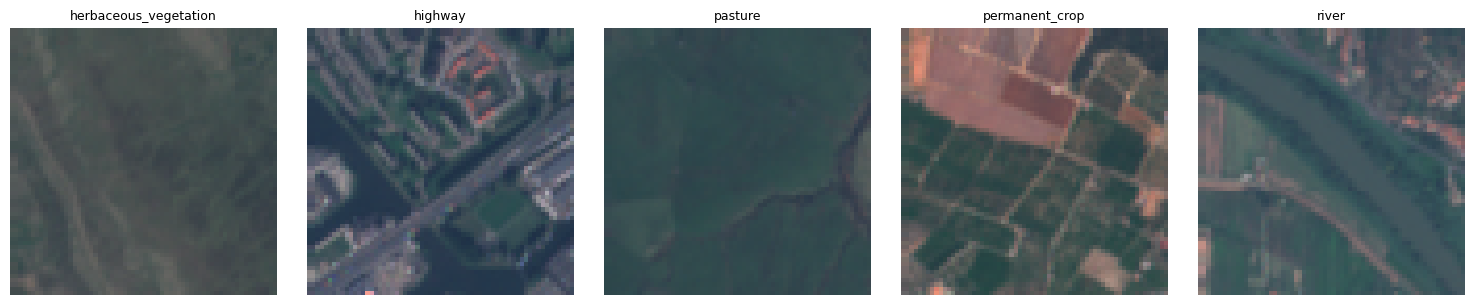

In [17]:

import os
import zipfile
import hashlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# 데이터 불러오기
train_3 = pd.read_csv('03_train.csv')
test_3 = pd.read_csv('03_test_x.csv')
label_3 = 'label'

# ZIP 압축 해제
img_dir_3 = Path(os.environ.get('AICE_IMG_DIR', '03_images_extracted'))

if not (img_dir_3 / '03_train').is_dir() or not (img_dir_3 / '03_test').is_dir():
    with zipfile.ZipFile('03_images.zip', 'r') as zf:
        zf.extractall(img_dir_3)

train_dir_3 = img_dir_3 / '03_train'
test_dir_3 = img_dir_3 / '03_test'

# 이미지 경로 생성
train_paths_3 = [
    train_dir_3 / label / filename
    for filename, label in zip(train_3['file_name'], train_3[label_3])
]

test_paths_3 = [
    test_dir_3 / filename
    for filename in test_3['file_name']
]

all_paths_3 = train_paths_3 + test_paths_3

print('학습 데이터:', train_3.shape)
print('테스트 데이터:', test_3.shape)

print('\n클래스별 이미지 수')
print(train_3[label_3].value_counts().sort_index().to_string())

print('\n이미지 파일 존재 여부')
print('학습 누락:', sum(not p.is_file() for p in train_paths_3))
print('테스트 누락:', sum(not p.is_file() for p in test_paths_3))

# 이미지 크기·채널·중복 확인
image_types_3 = Counter()
image_hashes_3 = []

for path in all_paths_3:
    with Image.open(path) as img:
        image_types_3[(img.size, img.mode)] += 1
        image_hashes_3.append(
            hashlib.sha256(img.tobytes()).hexdigest()
        )

print('\n이미지 크기 및 채널')
for (size, mode), count in image_types_3.items():
    print(size, mode, ':', count, '장')

print('\n동일 픽셀 중복 이미지:',
      len(image_hashes_3) - len(set(image_hashes_3)))

# 샘플 이미지 확인
classes_3 = sorted(train_3[label_3].unique())

fig, axes = plt.subplots(1, len(classes_3), figsize=(15, 3))

for ax, cls in zip(axes, classes_3):
    sample = train_3.loc[
        train_3[label_3] == cls, 'file_name'
    ].iloc[0]

    path = train_dir_3 / cls / sample

    with Image.open(path) as img:
        ax.imshow(img)

    ax.set_title(cls, fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()


In [18]:

import numpy as np
import pandas as pd

from PIL import Image
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# 이미지 로딩 및 0~1 정규화
def load_images_3(paths):
    images = []

    for path in paths:
        with Image.open(path) as img:
            img = img.convert('RGB')
            arr = np.asarray(img, dtype=np.float32) / 255.0
            images.append(arr)

    return np.stack(images)

# 학습 및 테스트 이미지 로딩
X_all_3 = load_images_3(train_paths_3)
X_test_3 = load_images_3(test_paths_3)

# 문자열 라벨을 정수로 변환
encoder_3 = LabelEncoder()
y_all_3 = encoder_3.fit_transform(train_3[label_3])

# 학습·검증 데이터 분리
X_train_3, X_valid_3, y_train_3, y_valid_3 = train_test_split(
    X_all_3,
    y_all_3,
    test_size=0.2,
    random_state=42,
    stratify=y_all_3
)

print('전체 이미지:', X_all_3.shape)
print('학습 이미지:', X_train_3.shape)
print('검증 이미지:', X_valid_3.shape)
print('테스트 이미지:', X_test_3.shape)

print('\n데이터 자료형:', X_train_3.dtype)
print('픽셀 최솟값:', X_train_3.min())
print('픽셀 최댓값:', X_train_3.max())

print('\n라벨 인코딩')
for idx, cls in enumerate(encoder_3.classes_):
    print(idx, ':', cls)

print('\n클래스별 학습·검증 분포')
distribution_3 = pd.DataFrame({
    '클래스': encoder_3.classes_,
    '학습': np.bincount(y_train_3, minlength=5),
    '검증': np.bincount(y_valid_3, minlength=5)
})
print(distribution_3.to_string(index=False))

print('\n정규화 확인:',
      0 <= X_train_3.min() <= X_train_3.max() <= 1)


전체 이미지: (1200, 64, 64, 3)
학습 이미지: (960, 64, 64, 3)
검증 이미지: (240, 64, 64, 3)
테스트 이미지: (300, 64, 64, 3)

데이터 자료형: float32
픽셀 최솟값: 0.07058824
픽셀 최댓값: 1.0

라벨 인코딩
0 : herbaceous_vegetation
1 : highway
2 : pasture
3 : permanent_crop
4 : river

클래스별 학습·검증 분포
                  클래스  학습  검증
herbaceous_vegetation 192  48
              highway 192  48
              pasture 192  48
       permanent_crop 192  48
                river 192  48

정규화 확인: True


In [19]:

import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, BatchNormalization,
    MaxPooling2D, Dropout,
    GlobalAveragePooling2D, Dense
)
from tensorflow.keras.optimizers import Adam

# 재현성을 위한 시드 설정
np.random.seed(42)
tf.random.set_seed(42)

# CNN 모델 구성
model_3 = Sequential([
    Input(shape=(64, 64, 3)),

    # Block 1
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.15),

    # Block 2
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.20),

    # Block 3
    Conv2D(128, (3, 3), padding='same', activation='relu'),
    Conv2D(128, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # 분류기
    GlobalAveragePooling2D(),
    Dense(64, activation='relu'),
    Dropout(0.30),
    Dense(5, activation='softmax')
])

# 모델 컴파일
model_3.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 모델 구조 확인
model_3.summary()

print('\n입력 형태:', model_3.input_shape)
print('출력 형태:', model_3.output_shape)
print('전체 파라미터:', model_3.count_params())


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 296,485 (1.13 MB)

 Trainable params: 296,037 (1.13 MB)

 Non-trainable params: 448 (1.75 KB)


입력 형태: (None, 64, 64, 3)
출력 형태: (None, 5)
전체 파라미터: 296485


In [20]:

import time
import numpy as np
import tensorflow as tf

from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report

# 최고 모델 저장 경로
checkpoint_3 = Path('answer_3_candidate_v1.keras')

if checkpoint_3.exists():
    raise FileExistsError('기존 체크포인트가 있습니다. 덮어쓰지 않습니다.')

# 학습 이미지 증강
def augment_3(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    return image, label

train_dataset_3 = (
    tf.data.Dataset.from_tensor_slices((X_train_3, y_train_3))
    .shuffle(len(X_train_3), seed=42)
    .map(augment_3, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

# 학습 콜백
callbacks_3 = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_3),
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        mode='max',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        mode='min',
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    )
]

# CNN 학습
start_3 = time.perf_counter()

history_3 = model_3.fit(
    train_dataset_3,
    validation_data=(X_valid_3, y_valid_3),
    epochs=35,
    callbacks=callbacks_3,
    verbose=1
)

elapsed_3 = time.perf_counter() - start_3

# 최고 Epoch 확인
best_epoch_3 = np.argmax(history_3.history['val_accuracy']) + 1
best_acc_3 = max(history_3.history['val_accuracy'])

# 저장된 최고 모델 불러오기
best_model_3 = tf.keras.models.load_model(checkpoint_3)

valid_loss_3, valid_acc_3 = best_model_3.evaluate(
    X_valid_3, y_valid_3, verbose=0
)

valid_probs_3 = best_model_3.predict(X_valid_3, verbose=0)
valid_pred_3 = np.argmax(valid_probs_3, axis=1)

print('\n학습 결과')
print('학습 Epoch:', len(history_3.history['loss']))
print('최고 Epoch:', best_epoch_3)
print('최고 기록 Accuracy:', round(best_acc_3, 4))
print('저장 모델 검증 Accuracy:', round(valid_acc_3, 4))
print('학습 소요 시간(초):', round(elapsed_3, 2))
print('저장 모델:', checkpoint_3)

print('\n클래스별 성능')
print(classification_report(
    y_valid_3,
    valid_pred_3,
    target_names=encoder_3.classes_,
    digits=4,
    zero_division=0
))


Epoch 1/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3868 - loss: 1.4506
Epoch 1: val_accuracy improved from None to 0.32083, saving model to answer_3_candidate_v1.keras

Epoch 1: finished saving model to answer_3_candidate_v1.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.4542 - loss: 1.2813 - val_accuracy: 0.3208 - val_loss: 1.5847 - learning_rate: 0.0010
Epoch 2/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5684 - loss: 1.0722   
Epoch 2: val_accuracy did not improve from 0.32083
30/30 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.5583 - loss: 1.1141 - val_accuracy: 0.2042 - val_loss: 1.6590 - learning_rate: 0.0010
Epoch 3/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5953 - loss: 0.9669   
Epoch 3: val_accuracy did not improve from 0.32083
30/30 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.5906 - loss: 0.9855 - val_accuracy: 0.2208 - val_loss: 1.8174 - learning_rate: 0.0010
Epoch 4/35
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 992ms/step - accuracy: 0.

In [21]:

import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path

# 기존 최고 체크포인트 사용
checkpoint_3 = Path('answer_3_candidate_v1.keras')
csv_path_3 = Path('answer_3_candidate_v1.csv')

if not checkpoint_3.is_file():
    raise FileNotFoundError('저장된 CNN 모델이 없습니다.')

if csv_path_3.exists():
    raise FileExistsError('기존 후보 CSV를 보호합니다.')

# 저장 모델 재불러오기
loaded_model_3 = tf.keras.models.load_model(checkpoint_3)

# 검증 정확도 재확인
valid_loss_3, valid_acc_3 = loaded_model_3.evaluate(
    X_valid_3,
    y_valid_3,
    verbose=0
)

# 테스트 예측
probs_before_3 = best_model_3.predict(
    X_test_3, verbose=0
)

probs_after_3 = loaded_model_3.predict(
    X_test_3, verbose=0
)

prediction_match_3 = np.allclose(
    probs_before_3,
    probs_after_3,
    rtol=1e-5,
    atol=1e-6
)

assert prediction_match_3, '저장 전후 예측값 불일치'

# 확률을 클래스 이름으로 변환
pred_idx_3 = np.argmax(probs_after_3, axis=1)
pred_labels_3 = encoder_3.inverse_transform(pred_idx_3)

assert len(pred_labels_3) == len(test_3)
assert pd.notna(pred_labels_3).all()
assert set(pred_labels_3).issubset(set(encoder_3.classes_))

# 원본 테스트 컬럼 유지
submission_3 = test_3.copy()
submission_3[label_3] = pred_labels_3

submission_3.to_csv(csv_path_3, index=False)

# CSV 재불러오기 및 검증
check_3 = pd.read_csv(csv_path_3)

assert check_3.shape == (300, 2)
assert check_3.columns.tolist() == (
    test_3.columns.tolist() + [label_3]
)
assert check_3['file_name'].equals(test_3['file_name'])
assert np.array_equal(
    check_3[label_3].values,
    pred_labels_3
)

print('저장 모델 검증 Accuracy:', round(valid_acc_3, 4))
print('모델 저장 전후 예측 일치:', prediction_match_3)
print('테스트 예측 건수:', len(pred_labels_3))
print('CSV 크기:', check_3.shape)
print('예측 결측치:', check_3[label_3].isna().sum())

print('\n클래스별 예측 분포')
print(check_3[label_3].value_counts().to_string())

print('\nCSV 미리보기')
print(check_3.head(10).to_string(index=False))

print('\n후보 모델:', checkpoint_3)
print('후보 CSV:', csv_path_3)
print('모델 크기:',
      round(checkpoint_3.stat().st_size / 1024 / 1024, 2),
      'MB')


저장 모델 검증 Accuracy: 0.8083
모델 저장 전후 예측 일치: True
테스트 예측 건수: 300
CSV 크기: (300, 2)
예측 결측치: 0

클래스별 예측 분포
label
herbaceous_vegetation    84
pasture                  65
highway                  59
permanent_crop           53
river                    39

CSV 미리보기
    file_name                 label
test_0001.png               pasture
test_0002.png herbaceous_vegetation
test_0003.png herbaceous_vegetation
test_0004.png               pasture
test_0005.png               highway
test_0006.png        permanent_crop
test_0007.png                 river
test_0008.png               pasture
test_0009.png herbaceous_vegetation
test_0010.png herbaceous_vegetation

후보 모델: answer_3_candidate_v1.keras
후보 CSV: answer_3_candidate_v1.csv
모델 크기: 3.47 MB


In [22]:

import shutil
import hashlib
import pandas as pd
from pathlib import Path

candidate_files_3 = {
    Path('answer_3_candidate_v1.keras'): Path('answer_3.keras'),
    Path('answer_3_candidate_v1.csv'): Path('answer_3.csv')
}

# 후보 파일 확인
for src in candidate_files_3:
    if not src.is_file():
        raise FileNotFoundError(f'후보 파일 없음: {src}')

# 기존 제출 파일 보호
for dst in candidate_files_3.values():
    if dst.exists():
        raise FileExistsError(f'기존 제출 파일 보호: {dst}')

# 정식 파일 생성
for src, dst in candidate_files_3.items():
    shutil.copy2(src, dst)

# 복사한 파일 내용 검증
for src, dst in candidate_files_3.items():
    src_hash = hashlib.sha256(src.read_bytes()).hexdigest()
    dst_hash = hashlib.sha256(dst.read_bytes()).hexdigest()
    assert src_hash == dst_hash, f'파일 불일치: {dst}'

# CSV 검증
check_final_3 = pd.read_csv('answer_3.csv')

assert check_final_3.shape == (300, 2)
assert check_final_3.columns.tolist() == (
    test_3.columns.tolist() + [label_3]
)
assert check_final_3['file_name'].equals(test_3['file_name'])
assert check_final_3[label_3].notna().all()
assert set(check_final_3[label_3]).issubset(
    set(encoder_3.classes_)
)

print('3번 정식 제출 파일 생성 완료')
print('모델: answer_3.keras')
print('예측: answer_3.csv')
print('제출 CSV:', check_final_3.shape)
print('후보 파일과 정식 파일 일치: True')

# 전체 제출 파일 확인
required_files_3 = [
    'answer_1.pkl',
    'answer_1.csv',
    'answer_2.pkl',
    'answer_2.csv',
    'answer_3.keras',
    'answer_3.csv'
]

print('\n전체 제출 파일 확인')
for filename in required_files_3:
    path = Path(filename)
    print(filename, ':', '정상' if path.is_file() else '누락')

assert all(Path(f).is_file() for f in required_files_3)
print('\n제출 파일 6개 확인 완료')


3번 정식 제출 파일 생성 완료
모델: answer_3.keras
예측: answer_3.csv
제출 CSV: (300, 2)
후보 파일과 정식 파일 일치: True

전체 제출 파일 확인
answer_1.pkl : 정상
answer_1.csv : 정상
answer_2.pkl : 정상
answer_2.csv : 정상
answer_3.keras : 정상
answer_3.csv : 정상

제출 파일 6개 확인 완료


<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

압축을 풀고 폴더 구조(학습: 클래스별 폴더, 테스트: 한 폴더)를 확인합니다. 이미지를 같은 크기로 읽어 0~1 로 맞추고, 검증 데이터를 떼어 **작은 CNN**(또는 사전학습 모델 특징 + 분류기)을 학습합니다. 증강·Dropout·조기 종료로 과적합을 막고, 테스트는 `03_test_x.csv` 순서대로 예측하세요.

- 이 문항의 핵심: 클래스별 폴더 구조이므로 `image_dataset_from_directory` 로 바로 읽을 수 있습니다(`validation_split`·`subset`·`seed` 로 검증 분리).

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `tensorflow`, `pandas`, `image_dataset_from_directory`, `load_img`, `img_to_array`, `Sequential`, `load_model`, `Input`, `Conv2D`, `MaxPooling2D`, `Flatten`, `Dense`, `Dropout`, `EarlyStopping`.

- 참고 문서: <https://keras.io/api/data_loading/image/>
- 참고 문서: <https://keras.io/api/data_loading/image/#loadimg-function>
- 참고 문서: <https://keras.io/api/data_loading/image/#imgtoarray-function>
- 참고 문서: <https://keras.io/api/models/sequential/>
- 참고 문서: <https://keras.io/api/layers/convolution_layers/convolution2d/>
- 참고 문서: <https://keras.io/api/layers/pooling_layers/max_pooling2d/>

</details>

<details><summary>힌트 3단계 (코드 구조) - 3번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
IMG_DIR = os.environ.get('____', '____')        # 압축을 풀 위치(브라우저판은 메모리 폴더 /tmp)
if not os.path.exists(os.path.join(IMG_DIR, '____')):
    zipfile.ZipFile('03_images.zip').extractall(IMG_DIR)
import ____
from tensorflow.keras.utils import ____, ____, ____
from tensorflow.keras.models import ____, ____
from tensorflow.keras.layers import ____, ____, ____, ____, ____, ____
from tensorflow.keras.callbacks import ____, ____, ____

train_csv = pd.read_csv('03_train.csv')
test = pd.read_csv('03_test_x.csv')
kw = dict(image_size=(____, ____), batch_size=____, validation_split=____, seed=____)
tr_ds = image_dataset_from_directory(f'____', subset='____', **kw)
va_ds = image_dataset_from_directory(f'____', subset='____', **kw)
CLASSES = tr_ds.class_names                               # 폴더 이름(알파벳 순) = 라벨 번호 순서

def to_numpy(ds):                                         # 배치를 모아 배열로(____~____ 정규화)
    xs, ys = zip(*[(np.asarray(x), np.asarray(y)) for x, y in ds])
    return np.concatenate(xs).astype('____') / ____, np.concatenate(ys)

# ▷ 모델 구성(CNN 또는 사전학습 특징 추출)
# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_3.h5`(모델) · `answer_3.csv`(예측)

</details>